# 第13章：从数据求主方向

**学生实验｜全书深化稿**

## 背景与数据
非共线四点用于协方差与特征向量；Wine用于降维后分类；Digits用于训练拟合后的重构。

## 本次要回答的问题
计算PCA方向、丢失SSE与解释方差，并比较后续分类而非只画投影。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 13: derive PCA directions, reconstruction and downstream comparisons."""
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from common import *

def run():
    X=np.array([[2.,1.],[1.,2.],[-1.,-2.],[-2.,-1.]])
    S=np.cov(X,rowvar=False);vals,vec=np.linalg.eigh(S);v=vec[:,-1]
    if v[0]<0:v=-v
    scores=X@v;recon=np.outer(scores,v)
    assert np.allclose(vals,[2/3,6]) and np.isclose(np.mean(np.sum((X-recon)**2,axis=1)),.5)
    table('ch13_hand',{'x1':X[:,0],'x2':X[:,1],'score':scores,'recon_x1':recon[:,0],'recon_x2':recon[:,1],'squared_distance':np.sum((X-recon)**2,axis=1)})
    dump('ch13_covariance',{'covariance':S,'eigenvalues_ascending':vals,'first_direction':v,'first_variance_ratio':.9})
    plt.figure(figsize=(5.6,5));plt.scatter(X[:,0],X[:,1],label='original');plt.scatter(recon[:,0],recon[:,1],marker='x',label='rank-one reconstruction')
    for a,b in zip(X,recon):plt.plot([a[0],b[0]],[a[1],b[1]],linestyle='--')
    z=np.linspace(-2.5,2.5,50);plt.plot(z,z);plt.xlabel('x1');plt.ylabel('x2');plt.axis('equal');plt.legend();figure('v3_ch13_geometry')
    X,y,_=development('wine');splits=list(cv5().split(X,y));rows=[]
    for k in [1,2,3,5,8,13]:
        m=make_pipeline(StandardScaler(),PCA(n_components=k,svd_solver='full'),LogisticRegression(max_iter=3000))
        r=cross_val_score(m,X,y,cv=splits);rows.append({'components':k,'accuracy_mean':r.mean(),'accuracy_std':r.std()})
    df=table('ch13_downstream',rows);show_result(df)
    Z=StandardScaler().fit_transform(X);p=PCA(svd_solver='full').fit(Z)
    table('ch13_variance',{'component':np.arange(1,14),'variance_ratio':p.explained_variance_ratio_,'cumulative':np.cumsum(p.explained_variance_ratio_)})
    # Reconstruction uses only training-fitted transform; this digit is held-out within development.
    Dt,Dv,yt,yv,_=development_trainval('digits');records=[]
    for k in [2,8,20,40]:
        p=PCA(k,svd_solver='full').fit(Dt);hat=p.inverse_transform(p.transform(Dv));mse=np.mean((Dv.to_numpy()-hat)**2)
        records.append({'components':k,'validation_pixel_MSE':mse})
    table('ch13_digits_reconstruction',records)
    plt.figure(figsize=(6.4,4));plt.plot(df.components,df.accuracy_mean,'o-');plt.xlabel('保留主成分数');plt.ylabel('五折验证准确率');figure('v3_ch13_components')

In [3]:
result = run()
if result is not None:
    print(result)

 components  accuracy_mean  accuracy_std
          1       0.859852      0.057302
          2       0.971921      0.026601
          3       0.958128      0.034200
          5       0.971921      0.026601
          8       0.978818      0.017301
         13       0.978818      0.017301


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch13_components.png


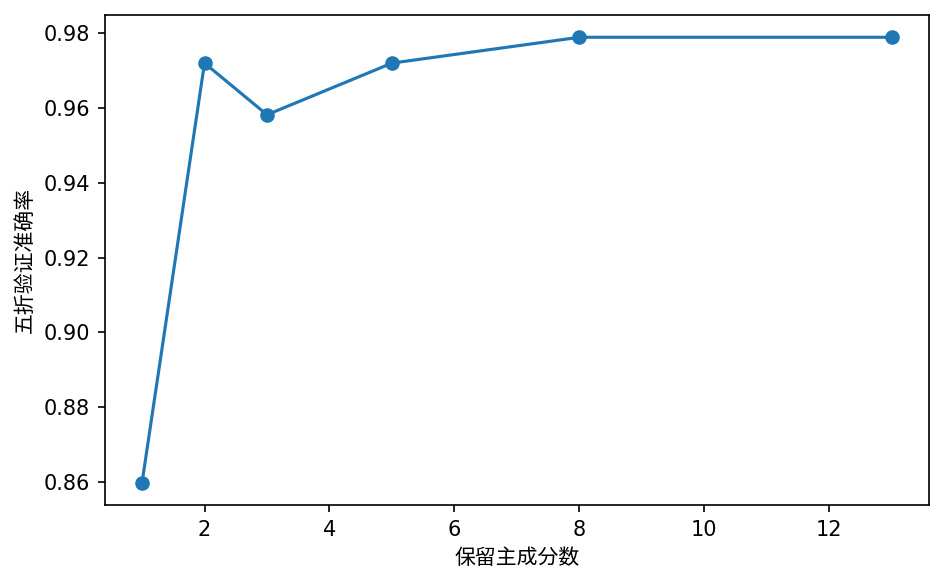

v3_ch13_geometry.png


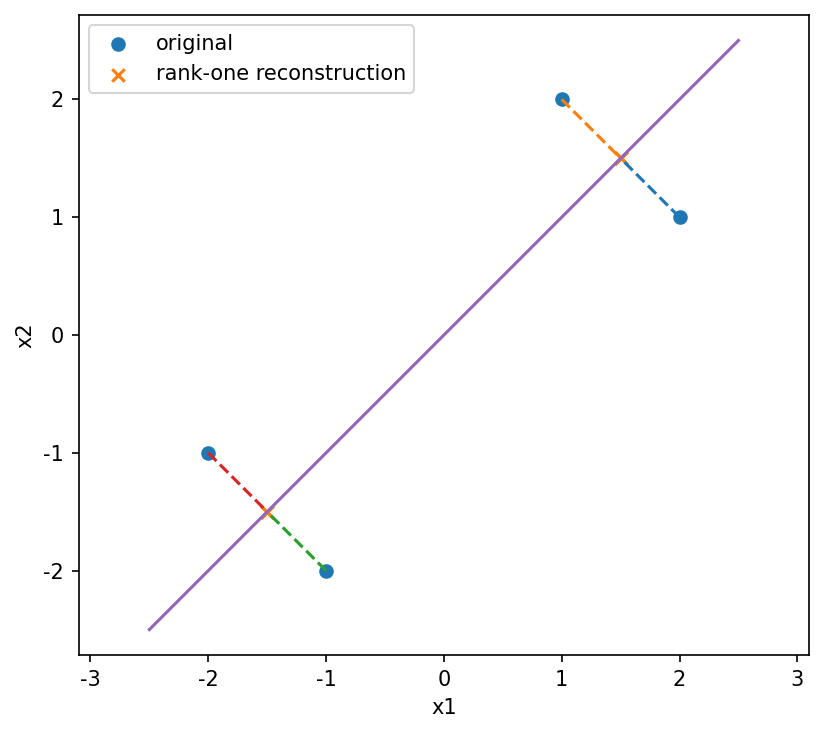

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch13_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

计算PCA方向、丢失SSE与解释方差，并比较后续分类而非只画投影。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。